In [1]:
import sys, subprocess, importlib

paquetes = {'seaborn': 'seaborn', 'statsmodels': 'statsmodels', 'sklearn': 'scikit-learn', 'scipy': 'scipy'}
for modulo, paquete in paquetes.items():
    try:
        importlib.import_module(modulo)
    except ImportError:
        print(f'Instalando {paquete}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', paquete])
importlib.invalidate_caches()

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay, ConfusionMatrixDisplay)

sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42
print('✅ Librerías cargadas correctamente')

✅ Librerías cargadas correctamente


In [2]:
url = "https://raw.githubusercontent.com/krishnaik06/Advanced-House-Price-Prediction-/master/train.csv"
df = pd.read_csv(url)
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print('Filas (casas):', df.shape[0])
print('Columnas (variables):', df.shape[1])

Filas (casas): 1460
Columnas (variables): 81


In [4]:
print(df.dtypes.value_counts())

num_cols = df.select_dtypes(include='number').columns.drop(['Id', 'SalePrice']).tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()

print(f'\nVariables numéricas: {len(num_cols)}')
print(num_cols)
print(f'\nVariables categóricas: {len(cat_cols)}')
print(cat_cols)

str        43
int64      35
float64     3
Name: count, dtype: int64

Variables numéricas: 36
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Variables categóricas: 43
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'Centr

In [5]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)

tabla_nulos = pd.DataFrame({
    'nulos': nulos,
    '% nulos': (nulos / len(df) * 100).round(2)
})
print(f'Columnas con nulos: {len(nulos)}')
tabla_nulos

Columnas con nulos: 19


,nulos,% nulos
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [6]:
#Duplicados
print('Filas duplicadas:', df.duplicated().sum())
print('Ids duplicados:', df['Id'].duplicated().sum())

Filas duplicadas: 0
Ids duplicados: 0


count      1460.0
mean     180921.2
std       79442.5
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

Sesgo (skew): 1.88
Curtosis: 6.54


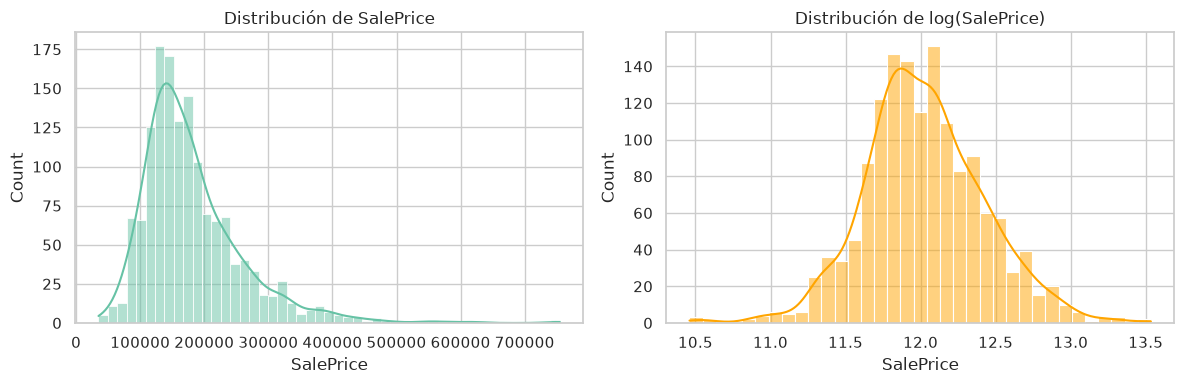

In [7]:
print(df['SalePrice'].describe().round(2))
print('\nSesgo (skew):', round(df['SalePrice'].skew(), 2))
print('Curtosis:', round(df['SalePrice'].kurt(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('Distribución de SalePrice')
sns.histplot(np.log1p(df['SalePrice']), kde=True, ax=axes[1], color='orange')
axes[1].set_title('Distribución de log(SalePrice)')
plt.tight_layout()
plt.show()

In [8]:
desc = df[num_cols].describe().T
desc['nulos'] = df[num_cols].isna().sum()
desc['sesgo'] = df[num_cols].skew()
desc['curtosis'] = df[num_cols].kurt()
desc['CV %'] = (desc['std'] / desc['mean'] * 100)
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,nulos,sesgo,curtosis,CV %
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0,0,1.41,1.58,74.35
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0,259,2.16,17.45,34.67
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0,0,12.21,203.24,94.91
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0,0,0.22,0.10,22.67
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0,0,0.69,1.11,19.96
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0,0,-0.61,-0.44,1.53
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0,0,-0.50,-1.27,1.04
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0,8,2.67,10.08,174.63
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0,0,1.69,11.12,102.81
BsmtFinSF2,1460.0,46.55,161.32,0.0,0.00,0.0,0.00,1474.0,0,4.26,20.11,346.56


Top 10 variables más correlacionadas con SalePrice:
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

Variables menos correlacionadas:
YrSold          -0.029
OverallCond     -0.078
MSSubClass      -0.084
EnclosedPorch   -0.129
KitchenAbvGr    -0.136
Name: SalePrice, dtype: float64


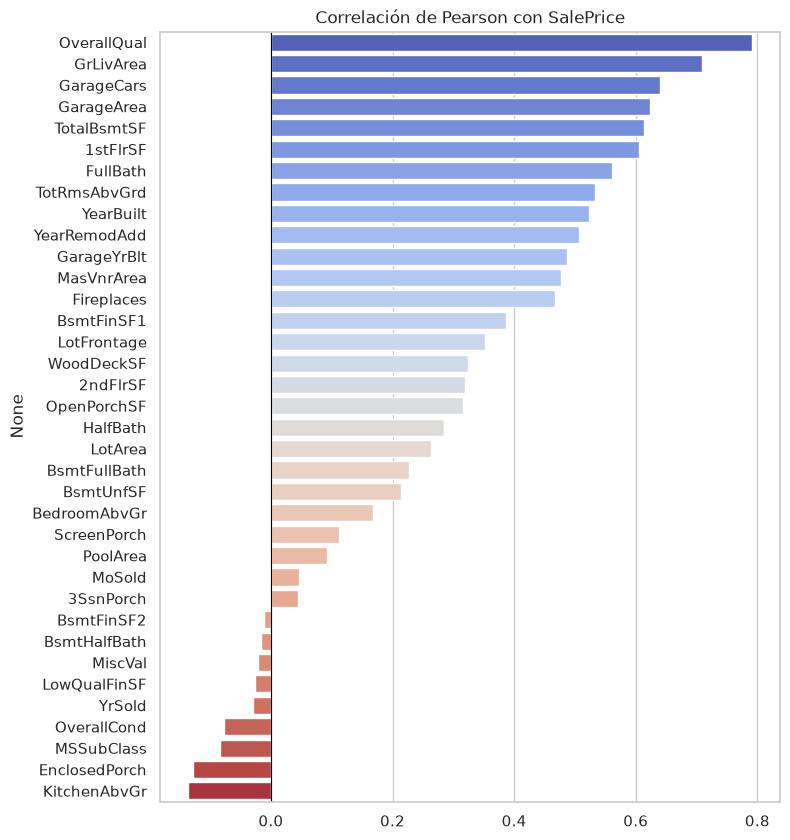

In [9]:
corr_target = df[num_cols + ['SalePrice']].corr()['SalePrice'].drop('SalePrice').sort_values(ascending=False)

print('Top 10 variables más correlacionadas con SalePrice:')
print(corr_target.head(10).round(3))
print('\nVariables menos correlacionadas:')
print(corr_target.tail(5).round(3))

plt.figure(figsize=(8, 10))
sns.barplot(x=corr_target.values, y=corr_target.index, palette='coolwarm')
plt.title('Correlación de Pearson con SalePrice')
plt.axvline(0, color='black', lw=0.8)
plt.show()

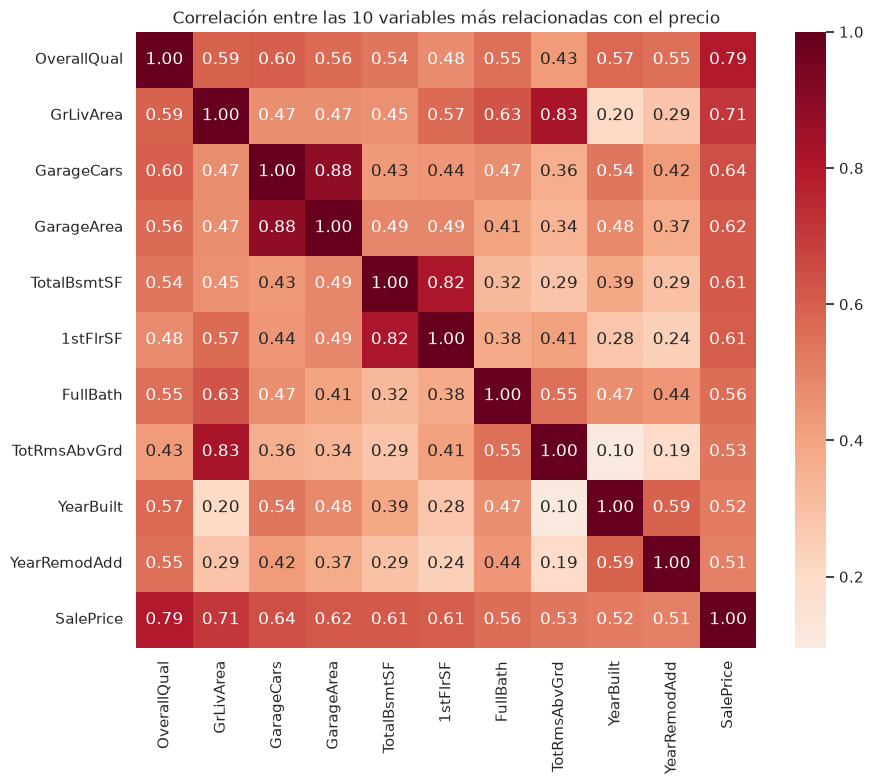

In [10]:
top10 = corr_target.head(10).index.tolist() + ['SalePrice']

plt.figure(figsize=(10, 8))
sns.heatmap(df[top10].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlación entre las 10 variables más relacionadas con el precio')
plt.show()

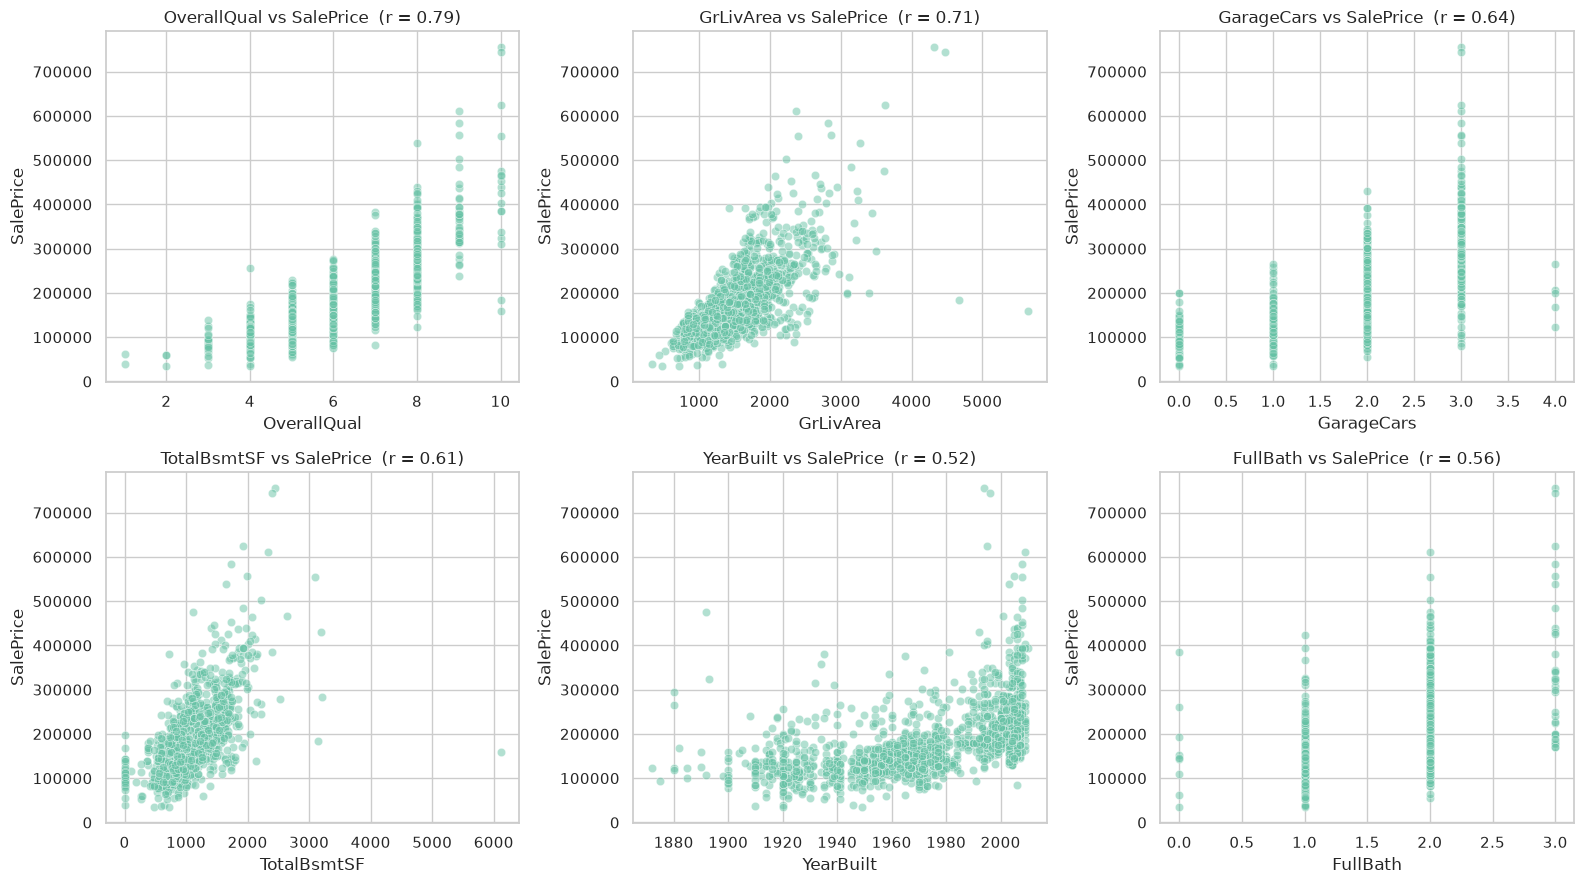

In [11]:
top_vars = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'FullBath']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.flat, top_vars):
    sns.scatterplot(data=df, x=c, y='SalePrice', ax=ax, alpha=0.5)
    ax.set_title(f'{c} vs SalePrice  (r = {corr_target[c]:.2f})')
plt.tight_layout()
plt.show()

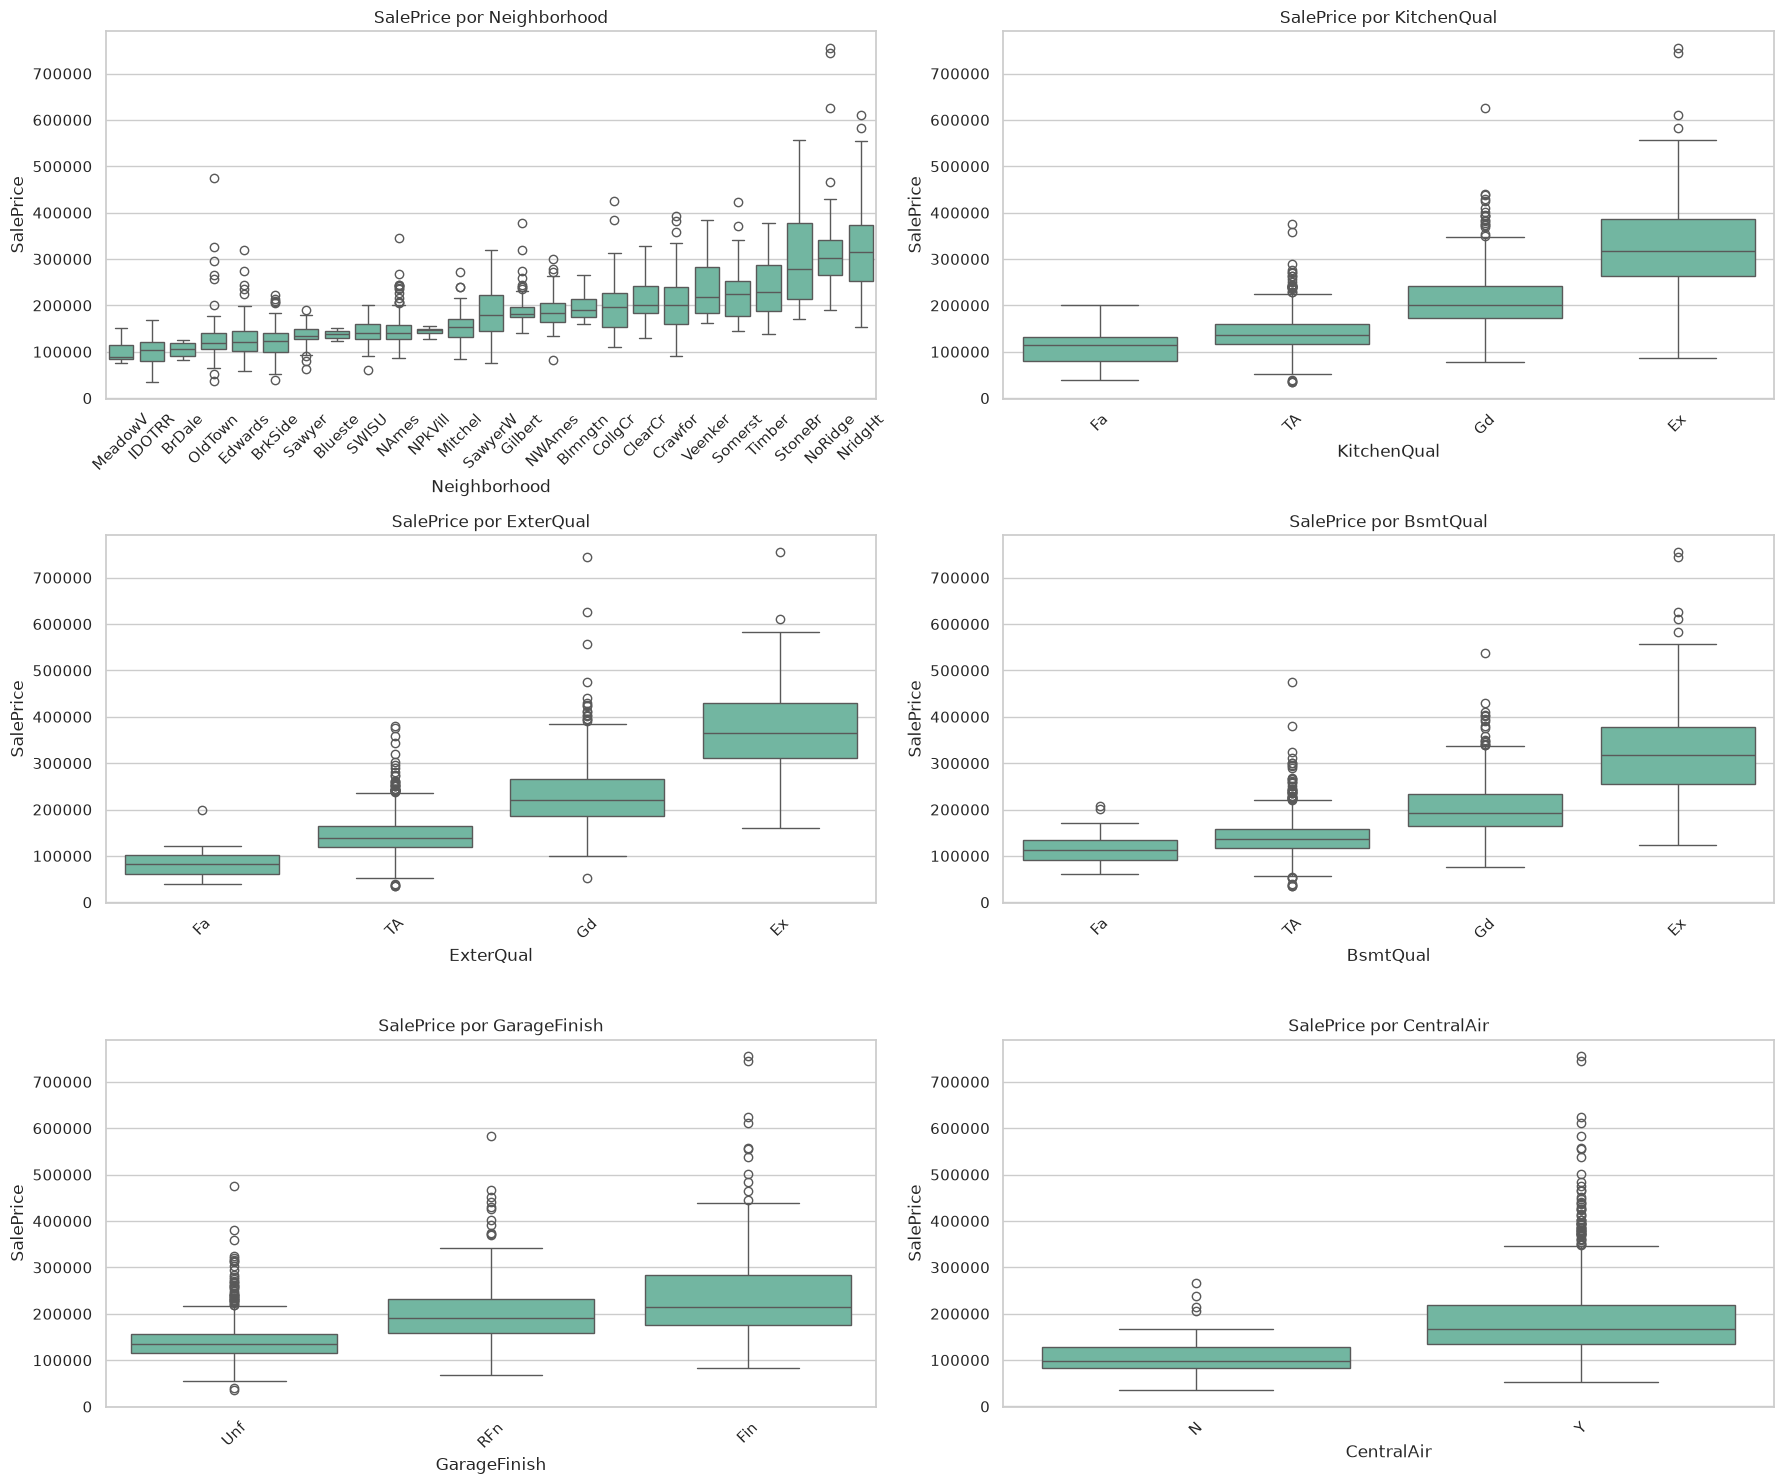

In [12]:
cat_show = ['Neighborhood', 'KitchenQual', 'ExterQual', 'BsmtQual', 'GarageFinish', 'CentralAir']

fig, axes = plt.subplots(3, 2, figsize=(18, 15))
for ax, c in zip(axes.flat, cat_show):
    orden = df.groupby(c)['SalePrice'].median().sort_values().index
    sns.boxplot(data=df, x=c, y='SalePrice', order=orden, ax=ax)
    ax.set_title(f'SalePrice por {c}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [13]:
rows = []
for c in cat_cols:
    grupos = [g['SalePrice'].values for _, g in df[[c, 'SalePrice']].dropna().groupby(c)]
    if len(grupos) > 1:
        f, p = stats.f_oneway(*grupos)
        rows.append({'variable': c, 'F': round(f, 2), 'p_value': p, 'categorías': df[c].nunique()})

anova = pd.DataFrame(rows).sort_values('F', ascending=False)
anova['significativa (α=0.05)'] = anova['p_value'] < 0.05
print(f"Significativas: {anova['significativa (α=0.05)'].sum()} de {len(anova)}")
anova

Significativas: 38 de 43


,variable,F,p_value,categorías,significativa (α=0.05)
18,ExterQual,443.33,1.439551e-204,4,True
30,KitchenQual,407.81,3.032213e-192,4,True
21,BsmtQual,392.91,9.610615e-186,4,True
34,GarageFinish,250.96,1.199117e-93,3,True
20,Foundation,100.25,5.791895e-91,6,True
28,CentralAir,98.31,1.809506e-22,2,True
27,HeatingQC,88.39,2.667062e-67,5,True
8,Neighborhood,71.78,1.558600e-225,25,True
33,GarageType,71.52,1.247154e-66,6,True
23,BsmtExposure,70.89,1.022671e-42,4,True


In [14]:
print('=== RESUMEN EDA ===')
print(f'Casas: {df.shape[0]}  |  Variables: {df.shape[1]}')
print(f'Numéricas: {len(num_cols)}  |  Categóricas: {len(cat_cols)}')
print(f'Columnas con nulos: {(df.isna().sum() > 0).sum()}')
print(f"Precio medio: ${df.SalePrice.mean():,.0f}  |  Mediana: ${df.SalePrice.median():,.0f}  |  Sesgo: {df.SalePrice.skew():.2f}")
print(f'\nTop 5 numéricas (correlación):\n{corr_target.head(5).round(3)}')
print(f"\nTop 5 categóricas (ANOVA F):\n{anova[['variable', 'F']].head(5).to_string(index=False)}")

=== RESUMEN EDA ===
Casas: 1460  |  Variables: 81
Numéricas: 36  |  Categóricas: 43
Columnas con nulos: 19
Precio medio: $180,921  |  Mediana: $163,000  |  Sesgo: 1.88

Top 5 numéricas (correlación):
OverallQual    0.791
GrLivArea      0.709
GarageCars     0.640
GarageArea     0.623
TotalBsmtSF    0.614
Name: SalePrice, dtype: float64

Top 5 categóricas (ANOVA F):
    variable      F
   ExterQual 443.33
 KitchenQual 407.81
    BsmtQual 392.91
GarageFinish 250.96
  Foundation 100.25


In [15]:
data = df.copy()
data = data.drop(columns=['Id'])
data['MSSubClass'] = data['MSSubClass'].astype(str)   # es un código de tipo de vivienda, no una cantidad
print(data.shape)

(1460, 80)


In [16]:
#Deteccion de outliers
vars_out = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'LotArea', '1stFlrSF', 'GarageArea']
rows = []
for c in vars_out:
    q1, q3 = data[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({'variable': c, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                 'lím_inf': round(lo, 1), 'lím_sup': round(hi, 1),
                 'outliers_IQR': ((data[c] < lo) | (data[c] > hi)).sum(),
                 'outliers_Z>3': (np.abs(stats.zscore(data[c])) > 3).sum()})
pd.DataFrame(rows)

,variable,Q1,Q3,IQR,lím_inf,lím_sup,outliers_IQR,outliers_Z>3
0,SalePrice,129975.00,214000.00,84025.00,3937.5,340037.5,61,22
1,GrLivArea,1129.50,1776.75,647.25,158.6,2747.6,31,16
2,TotalBsmtSF,795.75,1298.25,502.50,42.0,2052.0,61,10
3,LotArea,7553.50,11601.50,4048.00,1481.5,17673.5,69,13
4,1stFlrSF,882.00,1391.25,509.25,118.1,2155.1,20,12
5,GarageArea,334.50,576.00,241.50,-27.8,938.2,21,7


Casas anómalas:
      GrLivArea  TotalBsmtSF  OverallQual  SalePrice SaleCondition
523        4676         3138           10     184750       Partial
1298       5642         6110           10     160000       Partial


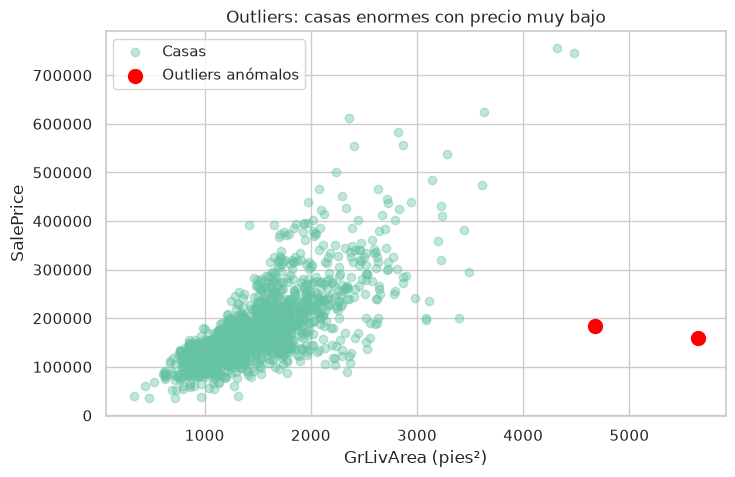

In [17]:
anomalos = data[(data['GrLivArea'] > 4000) & (data['SalePrice'] < 300000)]
print('Casas anómalas:')
print(anomalos[['GrLivArea', 'TotalBsmtSF', 'OverallQual', 'SalePrice', 'SaleCondition']])

plt.figure(figsize=(8, 5))
plt.scatter(data['GrLivArea'], data['SalePrice'], alpha=0.4, label='Casas')
plt.scatter(anomalos['GrLivArea'], anomalos['SalePrice'], color='red', s=100, label='Outliers anómalos')
plt.xlabel('GrLivArea (pies²)'); plt.ylabel('SalePrice')
plt.title('Outliers: casas enormes con precio muy bajo')
plt.legend(); plt.show()

Antes: (1460, 80)
Después: (1458, 80)


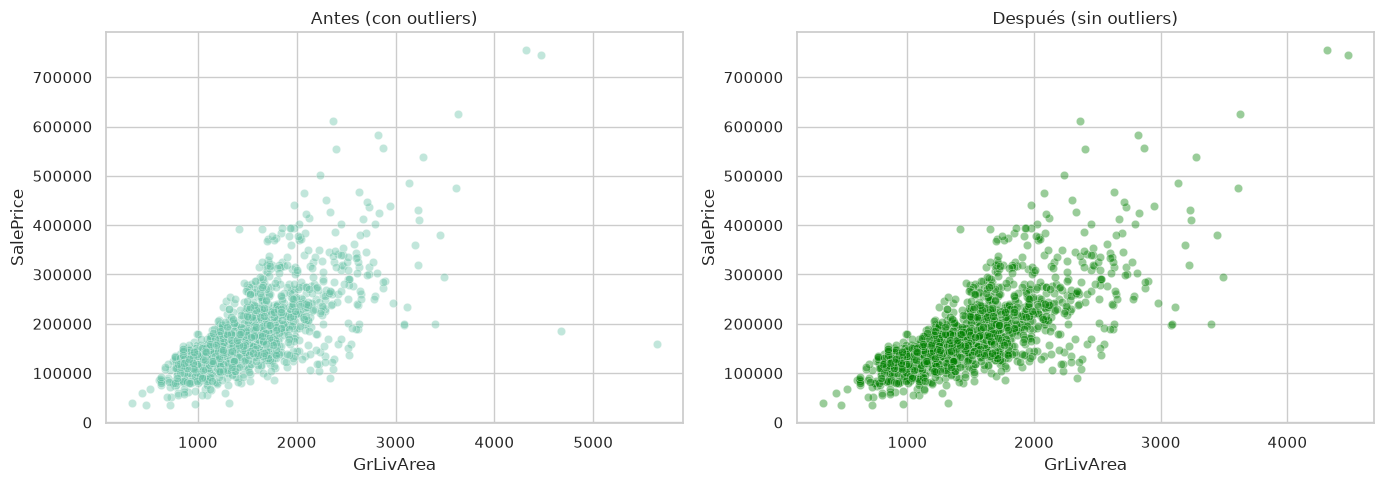

Correlación GrLivArea-SalePrice antes:   0.709
Correlación GrLivArea-SalePrice después: 0.735


In [18]:
print('Antes:', data.shape)
data = data.drop(anomalos.index).reset_index(drop=True)
print('Después:', data.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=df['GrLivArea'], y=df['SalePrice'], ax=axes[0], alpha=0.4)
axes[0].set_title('Antes (con outliers)')
sns.scatterplot(x=data['GrLivArea'], y=data['SalePrice'], ax=axes[1], alpha=0.4, color='green')
axes[1].set_title('Después (sin outliers)')
plt.tight_layout(); plt.show()

print('Correlación GrLivArea-SalePrice antes:  ', round(df['GrLivArea'].corr(df['SalePrice']), 3))
print('Correlación GrLivArea-SalePrice después:', round(data['GrLivArea'].corr(data['SalePrice']), 3))

In [19]:
nulos = data.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pd.DataFrame({'nulos': nulos, '%': (nulos / len(data) * 100).round(2), 'tipo': data[nulos.index].dtypes.astype(str)})

,nulos,%,tipo
PoolQC,1452,99.59,str
MiscFeature,1404,96.30,str
Alley,1367,93.76,str
Fence,1177,80.73,str
MasVnrType,872,59.81,str
FireplaceQu,690,47.33,str
LotFrontage,259,17.76,float64
GarageType,81,5.56,str
GarageYrBlt,81,5.56,float64
GarageFinish,81,5.56,str
